# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

1. **Одновыборочный z-тест**: сравниваем выборочное среднее с известным нормативом при известной дисперсии генеральной совокупности.
2. **Объединённый t-тест (Student)**: сравниваем средние двух независимых выборок с неизвестными, но одинаковыми дисперсиями; используется объединённая оценка дисперсии.
3. **Welch t-тест**: сравниваем средние независимых групп без предположения о равенстве их дисперсий.
4. **Однофакторный ANOVA**: одновременно проверяем равенство средних в трёх и более независимых группах, не увеличивая число отдельных t-проверок.
5. **Критерий хи-квадрат согласия**: сравниваем наблюдаемые частоты с теоретическими частотами распределения Пуассона (для корректности теста учитываем оценивание параметра и достаточность ожидаемых частот).

### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [2]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50
alpha = 0.05

# Известно стандартное отклонение генеральной совокупности -> двусторонний z-тест.
se = sigma / np.sqrt(n)
z_stat = (xbar - mu0) / se
p_value = 2 * stats.norm.sf(abs(z_stat))
critical_z = stats.norm.ppf(1 - alpha / 2)
ci_low, ci_high = xbar - critical_z * se, xbar + critical_z * se

print(f'z-статистика: {z_stat:.6f}')
print(f'p-value: {p_value:.8f}')
print(f'95% ДИ для среднего: [{ci_low:.6f}; {ci_high:.6f}] г')
print(f'Решение при a={alpha}: ' + ('отвергаем H0' if p_value < alpha else 'не отвергаем H0'))

z-статистика: 2.357023
p-value: 0.01842213
95% ДИ для среднего: [3.000842; 3.009158] г
Решение при a=0.05: отвергаем H0


**Вывод:** p-value < 0,05, а 95% доверительный интервал не содержит 3,00 г: средняя доза статистически значимо отличается от настройки. Стоит проверить и скорректировать калибровку дозатора; эксплуатационная необходимость перенастройки зависит также от допустимого технологического отклонения.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [3]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])
alpha = 0.05

n_a, n_b = len(A), len(B)
var_a, var_b = np.var(A, ddof=1), np.var(B, ddof=1)

levene_stat, levene_p = stats.levene(A, B)
f_stat = var_a / var_b
f_p = 2 * min(stats.f.cdf(f_stat, n_a - 1, n_b - 1),
              stats.f.sf(f_stat, n_a - 1, n_b - 1))
f_p = min(f_p, 1.0)


equal_var = (levene_p >= alpha) and (f_p >= alpha)
t_result = stats.ttest_ind(A, B, equal_var=equal_var, alternative='two-sided')
mean_diff = np.mean(A) - np.mean(B)

if equal_var:
    df = n_a + n_b - 2
    pooled_var = ((n_a - 1) * var_a + (n_b - 1) * var_b) / df
    se = np.sqrt(pooled_var * (1 / n_a + 1 / n_b))
    test_name = 'объединённый t-тест Стьюдента'
else:
    se = np.sqrt(var_a / n_a + var_b / n_b)
    df = (var_a / n_a + var_b / n_b) ** 2 / (
        (var_a / n_a) ** 2 / (n_a - 1) + (var_b / n_b) ** 2 / (n_b - 1)
    )
    test_name = 't-тест Уэлча'

margin = stats.t.ppf(1 - alpha / 2, df) * se
ci_low, ci_high = mean_diff - margin, mean_diff + margin

print(f'Критерий Левена: статистика = {levene_stat:.6f}; p-value = {levene_p:.6f}')
print(f'F-тест дисперсий: F = {f_stat:.6f}; p-value = {f_p:.6f}')
print(f'Выбранный тест: {test_name}')
print(f't-статистика: {t_result.statistic:.6f}; p-value = {t_result.pvalue:.6f}')
print(f'Разность средних (A − B): {mean_diff:.6f} МПа')
print(f'95% ДИ разности средних: [{ci_low:.6f}; {ci_high:.6f}] МПа')

Критерий Левена: статистика = 0.467598; p-value = 0.500926
F-тест дисперсий: F = 0.565564; p-value = 0.327105
Выбранный тест: объединённый t-тест Стьюдента
t-статистика: 0.317069; p-value = 0.754051
Разность средних (A − B): 0.587000 МПа
95% ДИ разности средних: [-3.242768; 4.416768] МПа


**Вывод:** Левен и двусторонний F-тест не отвергают равенство дисперсий (p > 0,05), поэтому применён объединённый t-тест. Различие средних статистически незначимо (p > 0,05), а 95% интервал для A − B включает ноль: доказательств превосходства одного материала нет.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [4]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after  = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before

alpha = 0.01  # уровень значимости основного теста
normality_alpha = 0.05
shapiro_stat, shapiro_p = stats.shapiro(diff)

# H1: среднее (после − до) < 0, то есть уровень глюкозы снизился.
if shapiro_p >= normality_alpha:
    result = stats.ttest_rel(after, before, alternative='less')
    test_name = 'парный односторонний t-тест'
else:
    result = stats.wilcoxon(after, before, alternative='less')
    test_name = 'односторонний критерий Уилкоксона'

print(f'Шапиро–Уилк: статистика = {shapiro_stat:.6f}; p-value = {shapiro_p:.6f}')
print(f'Выбранный тест: {test_name}')
print(f'Статистика теста: {result.statistic:.6f}')
print(f'p-value теста: {result.pvalue:.8f}')
print(f'Средняя разность (после − до): {np.mean(diff):.6f} ммоль/л')
print(f'Решение при a={alpha}: ' + ('отвергаем H0' if result.pvalue < alpha else 'не отвергаем H0'))

Шапиро–Уилк: статистика = 0.895967; p-value = 0.197745
Выбранный тест: парный односторонний t-тест
Статистика теста: -7.964862
p-value теста: 0.00001146
Средняя разность (после − до): -0.340000 ммоль/л
Решение при a=0.01: отвергаем H0


**Вывод:** Критерий Шапиро–Уилка не выявил отклонения распределения парных разностей от нормального (p > 0,05), поэтому выбран парный односторонний t-тест. При a = 0,01 снижение глюкозы статистически значимо (p < 0,01); в среднем показатель уменьшился на 0,34 ммоль/л.

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

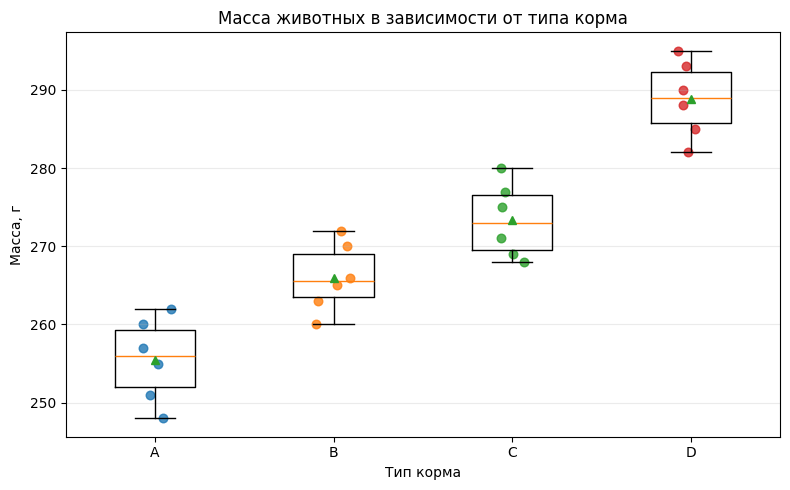

Группа A: среднее = 255.500 г; Шапиро–Уилк p-value = 0.879904
Группа B: среднее = 266.000 г; Шапиро–Уилк p-value = 0.916850
Группа C: среднее = 273.333 г; Шапиро–Уилк p-value = 0.648751
Группа D: среднее = 288.833 г; Шапиро–Уилк p-value = 0.941526
Левен: статистика = 0.129092; p-value = 0.941694
ANOVA: F-статистика = 49.924617; p-value = 0.000000001800

Tukey HSD:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------


In [5]:
A = [251,262,248,255,260,257]
B = [263,270,265,272,260,266]
C = [268,275,271,280,277,269]
D = [282,290,285,295,288,293]

alpha = 0.05
group_names = ['A', 'B', 'C', 'D']
groups = [np.asarray(g) for g in (A, B, C, D)]

np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(groups, tick_labels=group_names, showmeans=True)
for pos, group in enumerate(groups, start=1):
    jitter = np.random.uniform(-0.10, 0.10, size=len(group))
    ax.scatter(np.full(len(group), pos) + jitter, group, s=38, alpha=0.8)
ax.set_title('Масса животных в зависимости от типа корма')
ax.set_xlabel('Тип корма')
ax.set_ylabel('Масса, г')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

for name, group in zip(group_names, groups):
    shapiro_stat, shapiro_p = stats.shapiro(group)
    print(f'Группа {name}: среднее = {np.mean(group):.3f} г; '
          f'Шапиро–Уилк p-value = {shapiro_p:.6f}')
levene_stat, levene_p = stats.levene(*groups)
print(f'Левен: статистика = {levene_stat:.6f}; p-value = {levene_p:.6f}')

anova_stat, anova_p = stats.f_oneway(*groups)
print(f'ANOVA: F-статистика = {anova_stat:.6f}; p-value = {anova_p:.12f}')

if anova_p < alpha:
    observations = np.concatenate(groups)
    labels = np.concatenate([np.repeat(name, len(group))
                             for name, group in zip(group_names, groups)])
    tukey = pairwise_tukeyhsd(endog=observations, groups=labels, alpha=alpha)
    print('\nTukey HSD:')
    print(tukey.summary())
else:
    print('ANOVA незначима: Tukey HSD не проводим.')

**Вывод:** Шапиро–Уилк по каждой группе и Левен не выявили нарушений допущений при a = 0,05; ANOVA обнаружила значимые различия средних (p < 0,05). Корм D обеспечивает наибольшую среднюю массу (288,83 г) и по Tukey HSD статистически значимо превосходит A, B и C.

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [6]:
conv_c, n_c = 85, 1000     # контроль
conv_v, n_v = 120, 1000   # тест
alpha = 0.05

p_c, p_v = conv_c / n_c, conv_v / n_v
ci_c = proportion_confint(conv_c, n_c, alpha=alpha, method='wilson')
ci_v = proportion_confint(conv_v, n_v, alpha=alpha, method='wilson')

z_stat, p_value = proportions_ztest([conv_v, conv_c], [n_v, n_c], alternative='two-sided')

control = np.concatenate([np.ones(conv_c, dtype=int), np.zeros(n_c - conv_c, dtype=int)])
variant = np.concatenate([np.ones(conv_v, dtype=int), np.zeros(n_v - conv_v, dtype=int)])
np.random.seed(42)
n_boot = 20_000
boot_diff = np.empty(n_boot)
for i in range(n_boot):
    sample_c = np.random.choice(control, size=n_c, replace=True)
    sample_v = np.random.choice(variant, size=n_v, replace=True)
    boot_diff[i] = np.mean(sample_v) - np.mean(sample_c)
boot_ci_low, boot_ci_high = np.percentile(boot_diff, [2.5, 97.5])
point_diff = p_v - p_c

print(f'Контроль: конверсия = {p_c:.2%}; 95% ДИ Уилсона = [{ci_c[0]:.4%}; {ci_c[1]:.4%}]')
print(f'Тест:     конверсия = {p_v:.2%}; 95% ДИ Уилсона = [{ci_v[0]:.4%}; {ci_v[1]:.4%}]')
print(f'z-статистика: {z_stat:.6f}; p-value = {p_value:.8f}')
print(f'Разность конверсий (тест − контроль): {point_diff:.4f} ({point_diff*100:.2f} п.п.)')
print(f'95% бутстрэп-ДИ разности: [{boot_ci_low:.4f}; {boot_ci_high:.4f}]')
print(f'Решение при a={alpha}: ' + ('отвергаем H0' if p_value < alpha else 'не отвергаем H0'))

Контроль: конверсия = 8.50%; 95% ДИ Уилсона = [6.9263%; 10.3913%]
Тест:     конверсия = 12.00%; 95% ДИ Уилсона = [10.1299%; 14.1609%]
z-статистика: 2.580322; p-value = 0.00987083
Разность конверсий (тест − контроль): 0.0350 (3.50 п.п.)
95% бутстрэп-ДИ разности: [0.0080; 0.0620]
Решение при a=0.05: отвергаем H0


**Вывод:** Конверсия выросла с 8,5% до 12,0% (+3,5 п.п.), различие значимо при α = 0,05 (p < 0,05), а 95% бутстрэп-интервал для прироста не содержит ноль. Тестовый вариант можно рекомендовать к выкатке при корректно проведённой рандомизации и отсутствии ухудшения других важных метрик.